In [14]:
# Importing important libraries
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.datasets import load_diabetes
from sklearn.model_selection import train_test_split
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import accuracy_score, classification_report, confusion_matrix

In [4]:
# Load the dataset
data = load_diabetes(as_frame = True)

# Extract features and targets
X = data.data
y_continuous = data.target

In [5]:
# Convert the regression target into a binary classification problem
# We split patients into 0 (lower progression risk) and 1 (higher progression risk) based on the median score
median_threshold = y_continuous.median()
y = (y_continuous > median_threshold).astype(int)

In [6]:
# Split the dataset into training and testing sets (80% train, 20% test)
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.20, random_state=42, stratify=y
)

In [7]:
# Initialize and train the Random Forest Classifier
rf_classifier = RandomForestClassifier(n_estimators=100, random_state=42)
rf_classifier.fit(X_train, y_train)

RandomForestClassifier(random_state=42)

In [8]:
# Make predictions
y_pred = rf_classifier.predict(X_test)

=== Built-in Diabetes Classification ===
Accuracy Score: 0.7640

Confusion Matrix:
[[31 14]
 [ 7 37]]


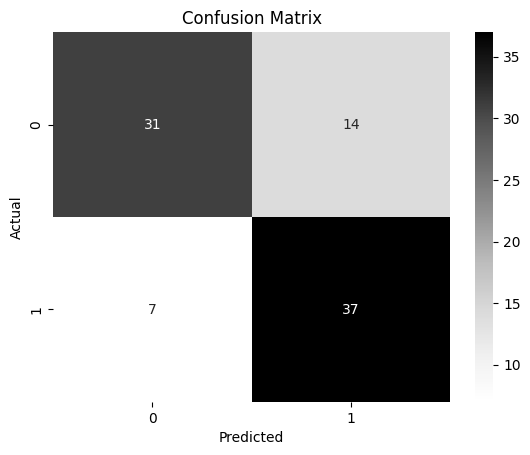


Classification Report:
              precision    recall  f1-score   support

    Low Risk       0.82      0.69      0.75        45
   High Risk       0.73      0.84      0.78        44

    accuracy                           0.76        89
   macro avg       0.77      0.76      0.76        89
weighted avg       0.77      0.76      0.76        89



In [16]:
# Let's evaluate the model
accuracy = accuracy_score(y_test, y_pred)
conf_matrix = confusion_matrix(y_test, y_pred)
class_report = classification_report(y_test, y_pred, target_names=['Low Risk', 'High Risk'])

print("=== Built-in Diabetes Classification ===")
print(f"Accuracy Score: {accuracy:.4f}\n")
print("Confusion Matrix:")
print(conf_matrix)

sns.heatmap(conf_matrix, annot=True, fmt='d', cmap='Greys')

plt.title('Confusion Matrix')
plt.xlabel('Predicted')
plt.ylabel('Actual')
plt.show()

print("\nClassification Report:")
print(class_report)

In [12]:
# Extract and Plot Feature Importances
importances = rf_classifier.feature_importances_
indices = np.argsort(importances)[::-1]
feature_names = X.columns

print("\n=== Feature Rankings ===")
for rank in range(X_train.shape[1]):
    print(f"{rank + 1}. {feature_names[indices[rank]]} ({importances[indices[rank]]:.4f})")


=== Feature Rankings ===
1. bmi (0.2056)
2. s5 (0.1749)
3. bp (0.1474)
4. s3 (0.0967)
5. s1 (0.0790)
6. s2 (0.0778)
7. s6 (0.0768)
8. age (0.0693)
9. s4 (0.0548)
10. sex (0.0179)


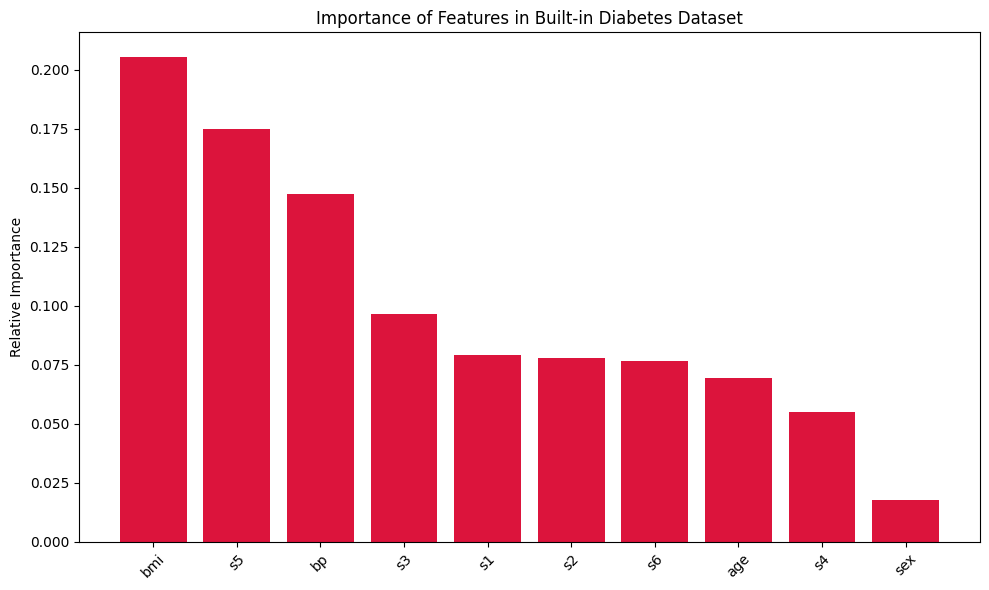

In [13]:
# Visualizing Feature Importance
plt.figure(figsize=(10, 6))
plt.title("Importance of Features in Built-in Diabetes Dataset")
plt.bar(range(X_train.shape[1]), importances[indices], align="center", color='crimson')
plt.xticks(range(X_train.shape[1]), [feature_names[i] for i in indices], rotation=45)
plt.ylabel('Relative Importance')
plt.tight_layout()
plt.show()